# 01 - Data Understanding
**Project:** Predicting Student Placement Probability Using Academic, Technical and Employability Features

**Phase scope:** data understanding only. No feature engineering, no modelling, no rows removed,
raw files are never modified. A processed copy (with audit flags only) is written to `data/processed/`.

**Source:** [Krooz/Campus_Recruitment_CSV](https://huggingface.co/datasets/Krooz/Campus_Recruitment_CSV)
(`raw_datasets/train.csv`, `validation.csv`, `test.csv`; licence CC0-1.0).

In [1]:
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
FIG, MET = ROOT / "results" / "figures", ROOT / "results" / "metrics"
for p in (PROC, FIG, MET):
    p.mkdir(parents=True, exist_ok=True)
TARGET = "PlacementStatus"

## 1. Load the raw data
The Hugging Face repo ships three pre-made splits. They are loaded as-is and stacked only for inspection; a `split` column records provenance.

In [2]:
splits = ["train", "validation", "test"]
frames = {}
for s in splits:
    f = RAW / f"{s}.csv"
    print(f"{f.name:16s} sha256={hashlib.sha256(f.read_bytes()).hexdigest()[:16]}...")
    frames[s] = pd.read_csv(f)
df = pd.concat([d.assign(split=s) for s, d in frames.items()], ignore_index=True)
print("\nSplit shapes:", {s: d.shape for s, d in frames.items()})
print("Identical columns across splits:", all(list(d.columns) == list(frames["train"].columns) for d in frames.values()))

train.csv        sha256=c9ee94194761275e...
validation.csv   sha256=6c3fd9fa80066a9d...
test.csv         sha256=8b9dc66f45bcedb6...

Split shapes: {'train': (7225, 11), 'validation': (1275, 11), 'test': (1500, 11)}
Identical columns across splits: True


## 2. Shape, columns and data types

In [3]:
print("Combined shape:", df.shape)
data_cols = [c for c in df.columns if c != "split"]
info = pd.DataFrame({"dtype": df[data_cols].dtypes.astype(str), "non_null": df[data_cols].notna().sum(),
                     "n_unique": df[data_cols].nunique()})
info

Combined shape: (10000, 12)


,dtype,non_null,n_unique
CGPA,float64,10000,27
Internships,int64,10000,3
Projects,int64,10000,4
Workshops/Certifications,int64,10000,4
AptitudeTestScore,int64,10000,31
SoftSkillsRating,float64,10000,19
ExtracurricularActivities,str,10000,2
PlacementTraining,str,10000,2
SSC_Marks,int64,10000,36
HSC_Marks,int64,10000,32


In [4]:
df.head(10)

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus,split
0,7.7,1,1,0,69,4.0,No,No,55,69,NotPlaced,train
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70,NotPlaced,train
2,7.0,1,1,1,64,4.1,No,No,58,62,NotPlaced,train
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80,Placed,train
4,6.7,0,2,1,71,3.7,No,No,55,67,NotPlaced,train
5,8.2,2,3,2,90,4.8,Yes,Yes,76,85,Placed,train
6,8.4,2,3,2,89,4.5,Yes,Yes,75,87,Placed,train
7,7.4,0,1,0,79,3.3,No,Yes,58,61,NotPlaced,train
8,7.2,1,2,2,75,4.3,No,Yes,75,75,NotPlaced,train
9,7.4,1,1,3,70,4.5,No,Yes,55,65,NotPlaced,train


## 3. Missing values

In [5]:
miss = pd.DataFrame({"missing": df[data_cols].isna().sum(), "pct": (df[data_cols].isna().mean() * 100).round(3)})
print("Total missing cells:", int(miss.missing.sum()))
miss

Total missing cells: 0


,missing,pct
CGPA,0,0.0
Internships,0,0.0
Projects,0,0.0
Workshops/Certifications,0,0.0
AptitudeTestScore,0,0.0
SoftSkillsRating,0,0.0
ExtracurricularActivities,0,0.0
PlacementTraining,0,0.0
SSC_Marks,0,0.0
HSC_Marks,0,0.0


In [6]:
# Hidden missingness: blank / whitespace-only strings or placeholder tokens
obj = df[data_cols].select_dtypes(exclude="number")
placeholders = {"", "na", "n/a", "nan", "null", "none", "-", "?", "unknown"}
hidden = {c: int(obj[c].astype(str).str.strip().str.lower().isin(placeholders).sum()) for c in obj}
print("Placeholder-like strings per object column:", hidden)

Placeholder-like strings per object column: {'ExtracurricularActivities': 0, 'PlacementTraining': 0, 'PlacementStatus': 0}


## 4. Duplicate rows
Duplicates are only *counted and flagged*. Nothing is dropped.

In [7]:
dup_all = df.duplicated(subset=data_cols, keep=False)      # every member of a duplicate group
dup_extra = df.duplicated(subset=data_cols, keep="first")  # surplus copies
print(f"Rows belonging to a duplicate group : {dup_all.sum()}")
print(f"Surplus copies (would be dropped)   : {dup_extra.sum()}  ({dup_extra.mean()*100:.2f}%)")
print("\nSurplus copies by split:\n", df[dup_extra].split.value_counts().to_string())
print("\nDuplicates within each split:", {s: int(d.duplicated().sum()) for s, d in frames.items()})

# Cross-split leakage: identical records appearing in more than one split
keys = df[data_cols].astype(str).agg("|".join, axis=1)
n_splits = df.assign(k=keys).groupby("k").split.nunique()
print("\nDistinct records present in >1 split (potential train/test leakage):", int((n_splits > 1).sum()))

Rows belonging to a duplicate group : 138
Surplus copies (would be dropped)   : 72  (0.72%)

Surplus copies by split:
 split
train         43
test          15
validation    14

Duplicates within each split: {'train': 43, 'validation': 0, 'test': 0}



Distinct records present in >1 split (potential train/test leakage): 28


In [8]:
# Do duplicate groups ever carry conflicting labels? (compare on features only)
feat_cols = [c for c in data_cols if c != TARGET]
g = df.groupby(feat_cols).agg(n=(TARGET, "size"), labels=(TARGET, "nunique")).reset_index()
print("Feature-identical groups with >1 row:", int((g.n > 1).sum()))
print("...of which have conflicting PlacementStatus labels:", int(((g.n > 1) & (g.labels > 1)).sum()))

Feature-identical groups with >1 row: 74
...of which have conflicting PlacementStatus labels: 8


## 5. Categorical columns - unique values

In [9]:
cat_cols = df[data_cols].select_dtypes(exclude="number").columns.tolist()
for c in cat_cols:
    print(f"--- {c} ---")
    print(df[c].value_counts(dropna=False).to_string(), "\n")
# Low-cardinality numeric columns that behave like categories/counts
for c in ["Internships", "Projects", "Workshops/Certifications"]:
    print(f"--- {c} (numeric count) ---")
    print(df[c].value_counts(dropna=False).sort_index().to_string(), "\n")

--- ExtracurricularActivities ---
ExtracurricularActivities
Yes    5854
No     4146 

--- PlacementTraining ---
PlacementTraining
Yes    7318
No     2682 

--- PlacementStatus ---
PlacementStatus
NotPlaced    5803
Placed       4197 

--- Internships (numeric count) ---
Internships
0    1983
1    5542
2    2475 

--- Projects (numeric count) ---
Projects
0      30
1    3547
2    2550
3    3873 

--- Workshops/Certifications (numeric count) ---
Workshops/Certifications
0    3739
1    2674
2    3303
3     284 



## 6. Descriptive statistics

In [10]:
num_cols = df[data_cols].select_dtypes(include="number").columns.tolist()
desc = df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = df[num_cols].skew(); desc["kurtosis"] = df[num_cols].kurt()
desc.round(3)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis
CGPA,10000.0,7.698,0.640,6.5,6.5,7.4,7.7,8.2,8.8,9.1,-0.403,-0.741
Internships,10000.0,1.049,0.666,0.0,0.0,1.0,1.0,1.0,2.0,2.0,-0.055,-0.748
Projects,10000.0,2.027,0.868,0.0,1.0,1.0,2.0,3.0,3.0,3.0,-0.079,-1.604
Workshops/Certifications,10000.0,1.013,0.904,0.0,0.0,0.0,1.0,2.0,3.0,3.0,0.205,-1.280
AptitudeTestScore,10000.0,79.450,8.160,60.0,60.0,73.0,80.0,87.0,90.0,90.0,-0.355,-0.854
SoftSkillsRating,10000.0,4.324,0.412,3.0,3.3,4.0,4.4,4.7,4.8,4.8,-0.676,-0.317
SSC_Marks,10000.0,69.159,10.430,55.0,55.0,59.0,70.0,78.0,89.0,90.0,0.034,-1.310
HSC_Marks,10000.0,74.502,8.920,57.0,58.0,67.0,73.0,83.0,88.0,88.0,-0.001,-1.412


In [11]:
df[cat_cols].describe().T

,count,unique,top,freq
ExtracurricularActivities,10000,2,Yes,5854
PlacementTraining,10000,2,Yes,7318
PlacementStatus,10000,2,NotPlaced,5803


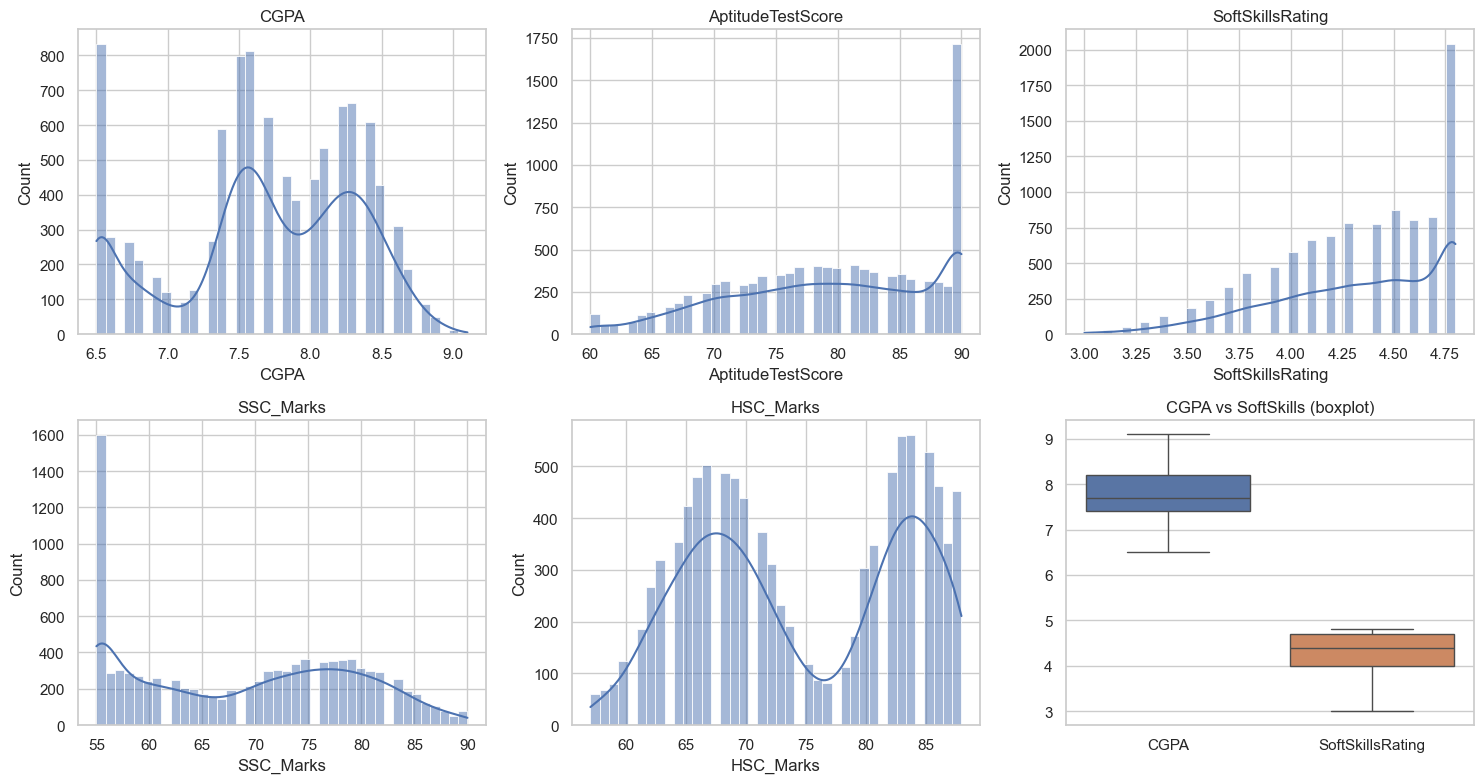

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), ["CGPA", "AptitudeTestScore", "SoftSkillsRating", "SSC_Marks", "HSC_Marks"]):
    sns.histplot(df[c], bins=40, kde=True, ax=ax); ax.set_title(c)
sns.boxplot(data=df[["CGPA", "SoftSkillsRating"]], ax=axes[1, 2]); axes[1, 2].set_title("CGPA vs SoftSkills (boxplot)")
plt.tight_layout(); plt.savefig(FIG / "01_numeric_distributions.png", dpi=150); plt.show()

## 7. Target distribution (`PlacementStatus`)

                 count    pct
PlacementStatus              
NotPlaced         5803  58.03
Placed            4197  41.97

By split (row %):
PlacementStatus  NotPlaced  Placed
split                             
test                 58.00   42.00
train                58.03   41.97
validation           58.04   41.96


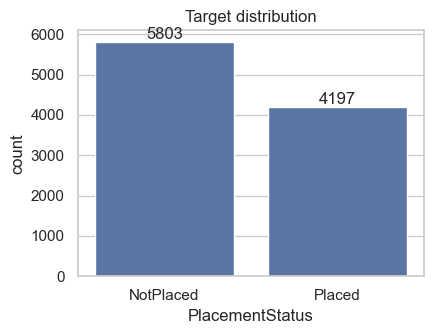

In [13]:
tc = df[TARGET].value_counts(dropna=False)
print(pd.DataFrame({"count": tc, "pct": (tc / len(df) * 100).round(2)}))
print("\nBy split (row %):")
print((pd.crosstab(df.split, df[TARGET], normalize="index") * 100).round(2))
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(data=df, x=TARGET, ax=ax); ax.set_title("Target distribution")
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG / "01_target_distribution.png", dpi=150); plt.show()

## 8. Impossible or suspicious values
Range checks use only what the dataset card and the data itself justify (marks/scores are percentages-like, CGPA is on a 10-point-style scale). Observed ranges are printed first so the thresholds below are not assumed blindly.

In [14]:
print(df[num_cols].agg(["min", "max"]).T)

                           min   max
CGPA                       6.5   9.1
Internships                0.0   2.0
Projects                   0.0   3.0
Workshops/Certifications   0.0   3.0
AptitudeTestScore         60.0  90.0
SoftSkillsRating           3.0   4.8
SSC_Marks                 55.0  90.0
HSC_Marks                 57.0  88.0


In [15]:
checks = {
    "CGPA outside [0, 10]":                  ~df.CGPA.between(0, 10),
    "SSC_Marks outside [0, 100]":            ~df.SSC_Marks.between(0, 100),
    "HSC_Marks outside [0, 100]":            ~df.HSC_Marks.between(0, 100),
    "AptitudeTestScore outside [0, 100]":    ~df.AptitudeTestScore.between(0, 100),
    "SoftSkillsRating outside [0, 5]":       ~df.SoftSkillsRating.between(0, 5),
    "Negative Internships/Projects/Workshops": (df[["Internships", "Projects", "Workshops/Certifications"]] < 0).any(axis=1),
    "Non-integer count columns":             (df[["Internships", "Projects", "Workshops/Certifications"]] % 1 != 0).any(axis=1),
}
rep = pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="n_rows")
rep

CGPA outside [0, 10]                       0
SSC_Marks outside [0, 100]                 0
HSC_Marks outside [0, 100]                 0
AptitudeTestScore outside [0, 100]         0
SoftSkillsRating outside [0, 5]            0
Negative Internships/Projects/Workshops    0
Non-integer count columns                  0
Name: n_rows, dtype: int64

In [16]:
# Statistical outliers (IQR rule, 1.5x) - informational, NOT errors.
# NB: for 3-4 valued count columns (e.g. Internships, IQR=0) the rule is meaningless and flags every non-modal value.
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append((c, lo, hi, int(((df[c] < lo) | (df[c] > hi)).sum())))
pd.DataFrame(rows, columns=["column", "lower_fence", "upper_fence", "n_outliers"]).set_index("column").round(2)

,lower_fence,upper_fence,n_outliers
column,,,
CGPA,6.20,9.40,0
Internships,1.00,1.00,4458
Projects,-2.00,6.00,0
Workshops/Certifications,-3.00,5.00,0
AptitudeTestScore,52.00,108.00,0
SoftSkillsRating,2.95,5.75,0
SSC_Marks,30.50,106.50,0
HSC_Marks,43.00,107.00,0


In [17]:
# Plausibility / logical consistency checks (flags only)
consistency = {
    "CGPA == 0 or very low (<5)":                 df.CGPA < 5,
    "SSC or HSC below 40":                        (df.SSC_Marks < 40) | (df.HSC_Marks < 40),
    "Many internships (>=4)":                     df.Internships >= 4,
    "Many projects (>=6)":                        df.Projects >= 6,
}
print(pd.Series({k: int(v.sum()) for k, v in consistency.items()}))
print("\nValue counts of SoftSkillsRating granularity (decimals):",
      (df.SoftSkillsRating * 10 % 1 != 0).sum(), "rows have >1 decimal place")

CGPA == 0 or very low (<5)    0
SSC or HSC below 40           0
Many internships (>=4)        0
Many projects (>=6)           0
dtype: int64

Value counts of SoftSkillsRating granularity (decimals): 0 rows have >1 decimal place


## 9. Relationships snapshot (descriptive only, not modelling)
Looking for constant features, leakage-like signals and redundancy.

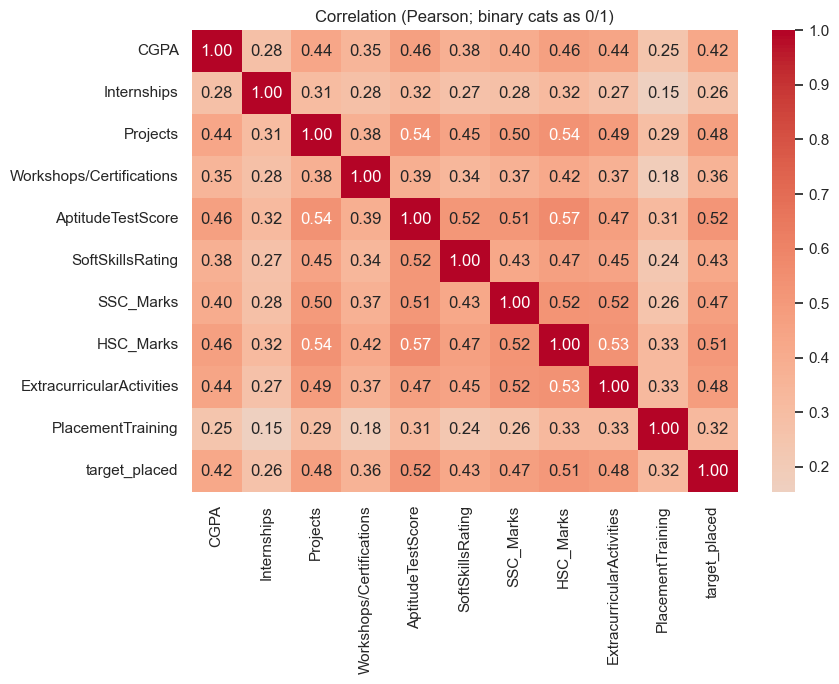

AptitudeTestScore            0.522
HSC_Marks                    0.506
ExtracurricularActivities    0.482
Projects                     0.475
SSC_Marks                    0.470
SoftSkillsRating             0.427
CGPA                         0.423
Workshops/Certifications     0.362
PlacementTraining            0.324
Internships                  0.260
Name: target_placed, dtype: float64

In [18]:
y = (df[TARGET] == "Placed").astype(int)  # temporary numeric view, not stored as a feature
enc = df[num_cols].copy()
for c in ["ExtracurricularActivities", "PlacementTraining"]:
    enc[c] = (df[c] == "Yes").astype(int)
enc["target_placed"] = y
corr = enc.corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax); ax.set_title("Correlation (Pearson; binary cats as 0/1)")
plt.tight_layout(); plt.savefig(FIG / "01_correlation_heatmap.png", dpi=150); plt.show()
corr["target_placed"].drop("target_placed").sort_values(key=abs, ascending=False).round(3)

In [19]:
# Placement rate by categorical / count features
for c in ["ExtracurricularActivities", "PlacementTraining", "Internships", "Projects", "Workshops/Certifications"]:
    t = df.groupby(c)[TARGET].agg(n="size", placed_rate=lambda s: round((s == "Placed").mean(), 3))
    print(f"--- {c} ---"); print(t.to_string(), "\n")
# Are train/val/test drawn from similar distributions?
for c in ["CGPA", "AptitudeTestScore", "SSC_Marks", "HSC_Marks"]:
    a, b = frames["train"][c], frames["test"][c]
    print(f"KS train vs test  {c:18s} stat={stats.ks_2samp(a, b).statistic:.3f}  p={stats.ks_2samp(a, b).pvalue:.3f}")

--- ExtracurricularActivities ---
                              n  placed_rate
ExtracurricularActivities                   
No                         4146        0.137
Yes                        5854        0.620 

--- PlacementTraining ---
                      n  placed_rate
PlacementTraining                   
No                 2682        0.156
Yes                7318        0.516 

--- Internships ---
                n  placed_rate
Internships                   
0            1983        0.334
1            5542        0.326
2            2475        0.697 

--- Projects ---
             n  placed_rate
Projects                   
0           30        0.600
1         3547        0.169
2         2550        0.314
3         3873        0.718 

--- Workshops/Certifications ---
                             n  placed_rate
Workshops/Certifications                   
0                         3739        0.284
1                         2674        0.211
2                         3303     

In [20]:
# Class separation per numeric feature
cmp = df.groupby(TARGET)[num_cols].mean().T
cmp["abs_diff_in_sd"] = ((cmp.get("Placed") - cmp.get("NotPlaced")).abs() / df[num_cols].std()).round(3)
cmp.round(3)

PlacementStatus,NotPlaced,Placed,abs_diff_in_sd
CGPA,7.468,8.016,0.857
Internships,0.902,1.253,0.528
Projects,1.676,2.512,0.963
Workshops/Certifications,0.735,1.398,0.734
AptitudeTestScore,75.829,84.456,1.057
SoftSkillsRating,4.174,4.531,0.866
SSC_Marks,64.993,74.921,0.952
HSC_Marks,70.665,79.806,1.025


## 10. Data-quality issue register
Populated programmatically from the checks above; interpretation is in the markdown cell after it.

In [21]:
issues = []
issues.append(("Missing values", int(df[data_cols].isna().sum().sum())))
issues.append(("Surplus duplicate rows", int(dup_extra.sum())))
issues.append(("Rows in any duplicate group", int(dup_all.sum())))
issues.append(("Records appearing in >1 split", int((n_splits > 1).sum())))
issues += [(k, int(v.sum())) for k, v in checks.items()]
issues.append(("Target imbalance (minority %)", round(float(tc.min() / tc.sum() * 100), 2)))
issue_df = pd.DataFrame(issues, columns=["check", "value"])
issue_df.to_csv(MET / "01_data_quality_summary.csv", index=False)
issue_df

,check,value
0,Missing values,0.00
1,Surplus duplicate rows,72.00
2,Rows in any duplicate group,138.00
3,Records appearing in >1 split,28.00
4,"CGPA outside [0, 10]",0.00
5,"SSC_Marks outside [0, 100]",0.00
6,"HSC_Marks outside [0, 100]",0.00
7,"AptitudeTestScore outside [0, 100]",0.00
8,"SoftSkillsRating outside [0, 5]",0.00
9,Negative Internships/Projects/Workshops,0.00


## 11. Save a processed copy (no rows removed, no values changed)
The processed file is the stacked data plus audit columns: `split`, `is_duplicate_extra` (surplus copy flag) and `is_in_dup_group`. Downstream phases decide what to do with the flags.

In [22]:
out = df.copy()
out["is_duplicate_extra"] = dup_extra.values
out["is_in_dup_group"] = dup_all.values
out.to_csv(PROC / "campus_recruitment_combined_flagged.csv", index=False)
desc.round(4).to_csv(MET / "01_descriptive_statistics.csv")
print("Saved:", out.shape, "->", PROC / "campus_recruitment_combined_flagged.csv")
assert len(out) == sum(len(d) for d in frames.values()), "row count changed!"
# raw files untouched check
for s in splits:
    assert pd.read_csv(RAW / f"{s}.csv").equals(frames[s])
print("Raw files unchanged; no rows removed.")

Saved: (10000, 14) -> D:\Student-Placement-Prediction\student-placement-prediction\data\processed\campus_recruitment_combined_flagged.csv
Raw files unchanged; no rows removed.


## 12. Summary of findings
| Item | Finding |
|---|---|
| Shape | 10,000 rows x 11 columns (train 7,225 / validation 1,275 / test 1,500 pre-made splits) |
| Types | 8 numeric (CGPA, SoftSkillsRating float; others int), 3 text (ExtracurricularActivities, PlacementTraining, PlacementStatus) |
| Missing | 0 missing cells; no placeholder strings |
| Duplicates | 72 surplus exact copies (0.72%); 138 rows sit in duplicate groups; 28 distinct records appear in more than one split (leakage risk); 8 feature-identical groups carry conflicting labels |
| Target | NotPlaced 5,803 (58.03%) / Placed 4,197 (41.97%); mild imbalance, identical across splits |
| Range violations | None: every column lies inside its plausible range |
| Observed ranges | CGPA 6.5-9.1, Aptitude 60-90, SoftSkills 3.0-4.8, SSC 55-90, HSC 57-88: all hard-bounded (no tails), so unusually clean |
| Odd patterns | `Projects=0` has only 30 rows; placement rate is non-monotonic in Internships (0:33% vs 1:33% vs 2:70%) and Workshops (0:28%, 1:21%, 2:73%, 3:56%) |
| IQR outliers | Only an artefact for `Internships` (IQR=0); no genuine outliers elsewhere |

**Caveat:** the dataset card does not state whether the data is real or synthetic; the bounded ranges and the very strong,
non-monotonic effects are consistent with synthetic generation, but this is an observation, not a conclusion.